In [1]:
#Step 1: Install dependencies (run once in terminal)
! pip install pandas matplotlib

In [2]:
#Step 2: Load the CSV, skipping the 7 header/note rows
import pandas as pd
import matplotlib.pyplot as plt

FILE = "202601_ChS.csv"

df = pd.read_csv(FILE, skiprows=7, encoding="utf-8-sig")
print(df.head())
print(df.shape)

           日期  时间 中西区 南区 东区  观塘 深水埗  葵涌 荃湾 将军澳 元朗 屯门 东涌 大埔  沙田 北区 塔门 铜锣湾 中环 旺角
0  2026-01-01  01   4  4  4   4   4   4  4   4  4  5  3  4   4  4  4   4  4  4
1         NaN  02   4  4  4   4   4   4  4   4  3  4  3  4   4  4  4   4  4  4
2         NaN  03   4  4  4   4   4   4  3   4  3  4  3  4   4  4  4   4  4  4
3         NaN  04   4  4  4   4   3   4  3   4  3  4  3  4   4  4  4   3  4  4
4         NaN  05   4  4  4  4*   3  3*  3   4  3  4  3  3  3*  4  3   3  3  4
(775, 20)


In [3]:
#Step 3: Remove the "daily maximum" summary rows, keeping only hourly observations
df = df[df["时间"].astype(str).str.strip() != "每日最高值"].copy()
print(df["时间"].unique()[:10])
print(df.shape)

<ArrowStringArray>
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10']
Length: 10, dtype: str
(744, 20)


In [4]:
#Step 4: Forward-fill the date column because it only appears on each day's first row
df["日期"] = df["日期"].ffill()
print(df[["日期", "时间"]].head(30))

            日期  时间
0   2026-01-01  01
1   2026-01-01  02
2   2026-01-01  03
3   2026-01-01  04
4   2026-01-01  05
5   2026-01-01  06
6   2026-01-01  07
7   2026-01-01  08
8   2026-01-01  09
9   2026-01-01  10
10  2026-01-01  11
11  2026-01-01  12
12  2026-01-01  13
13  2026-01-01  14
14  2026-01-01  15
15  2026-01-01  16
16  2026-01-01  17
17  2026-01-01  18
18  2026-01-01  19
19  2026-01-01  20
20  2026-01-01  21
21  2026-01-01  22
22  2026-01-01  23
23  2026-01-01  24
25  2026-01-02  01
26  2026-01-02  02
27  2026-01-02  03
28  2026-01-02  04
29  2026-01-02  05
30  2026-01-02  06


In [5]:
#Step 5: Identify the 18 station columns (everything except date and time)
station_cols = [c for c in df.columns if c not in ["日期", "时间"]]
print(len(station_cols), station_cols)

18 ['中西区', '南区', '东区', '观塘', '深水埗', '葵涌', '荃湾', '将军澳', '元朗', '屯门', '东涌', '大埔', '沙田', '北区', '塔门', '铜锣湾', '中环', '旺角']


In [6]:
#Step 6: Clean AQHI values by treating "-" as missing, stripping "*", and mapping "10+" to 10
def clean_aqhi(x):
    if pd.isna(x):
        return pd.NA
    s = str(x).strip()
    if s in ["-", "", "-*"]:
        return pd.NA
    s = s.replace("*", "")
    if s == "10+":
        return 10.0
    try:
        return float(s)
    except ValueError:
        return pd.NA

for col in station_cols:
    df[col] = df[col].apply(clean_aqhi)

print(df[station_cols].head())
print(df[station_cols].dtypes)


   中西区   南区   东区   观塘  深水埗   葵涌   荃湾  将军澳   元朗   屯门   东涌   大埔   沙田   北区   塔门  \
0  4.0  4.0  4.0  4.0  4.0  4.0  4.0  4.0  4.0  5.0  3.0  4.0  4.0  4.0  4.0   
1  4.0  4.0  4.0  4.0  4.0  4.0  4.0  4.0  3.0  4.0  3.0  4.0  4.0  4.0  4.0   
2  4.0  4.0  4.0  4.0  4.0  4.0  3.0  4.0  3.0  4.0  3.0  4.0  4.0  4.0  4.0   
3  4.0  4.0  4.0  4.0  3.0  4.0  3.0  4.0  3.0  4.0  3.0  4.0  4.0  4.0  4.0   
4  4.0  4.0  4.0  4.0  3.0  3.0  3.0  4.0  3.0  4.0  3.0  3.0  3.0  4.0  3.0   

   铜锣湾   中环   旺角  
0  4.0  4.0  4.0  
1  4.0  4.0  4.0  
2  4.0  4.0  4.0  
3  3.0  4.0  4.0  
4  3.0  3.0  4.0  
中西区    float64
南区     float64
东区     float64
观塘     float64
深水埗    float64
葵涌     float64
荃湾     float64
将军澳    float64
元朗     float64
屯门     float64
东涌     float64
大埔      object
沙田      object
北区      object
塔门      object
铜锣湾    float64
中环     float64
旺角     float64
dtype: object


In [7]:
#Step 7: Convert the time column to numeric hours

df["时间"] = pd.to_numeric(df["时间"], errors="coerce")
print(df["时间"].describe())

count    744.000000
mean      12.500000
std        6.926843
min        1.000000
25%        6.750000
50%       12.500000
75%       18.250000
max       24.000000
Name: 时间, dtype: float64


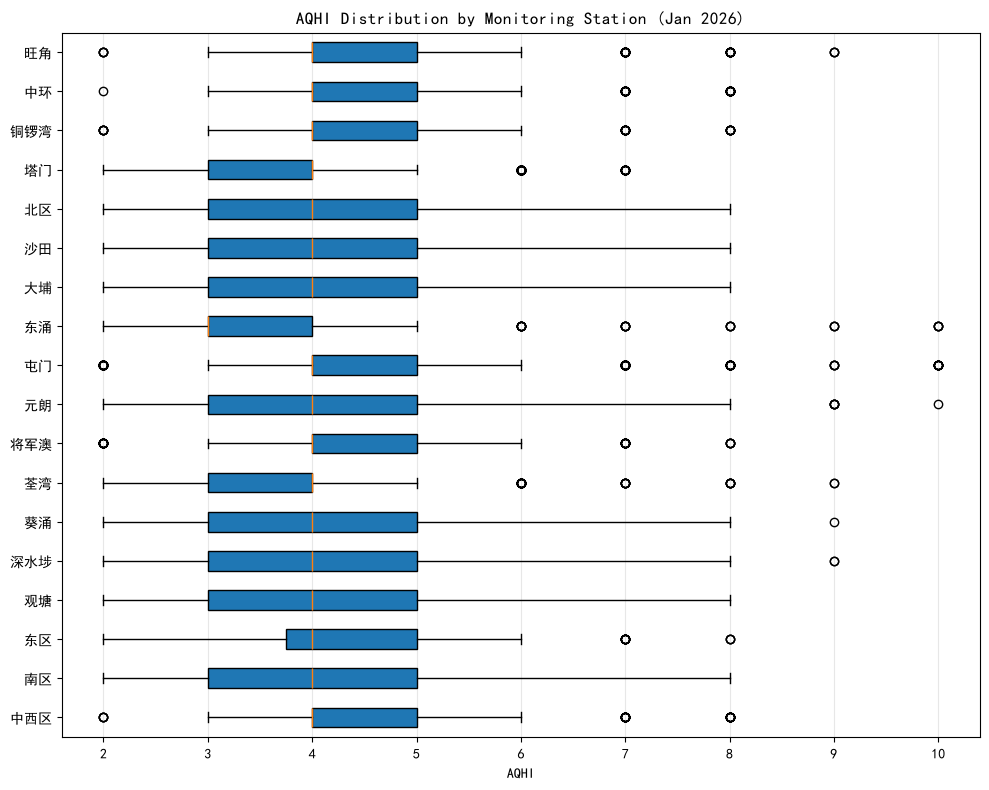

In [8]:
# Step 8: Draw Figure A, a horizontal boxplot of AQHI distribution per station, save and show it

%matplotlib inline
plt.rcParams['font.sans-serif'] = ['SimHei']  
plt.rcParams['axes.unicode_minus'] = False    

plot_df = df.dropna(subset=station_cols, how="all")

fig, ax = plt.subplots(figsize=(10, 8))
data = [plot_df[c].dropna().astype(float) for c in station_cols]
ax.boxplot(data, orientation="horizontal", tick_labels=station_cols, patch_artist=True) 
ax.set_xlabel("AQHI")
ax.set_title("AQHI Distribution by Monitoring Station (Jan 2026)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig("fig1_station_boxplot.png", dpi=150)  
plt.show()                                        


In [9]:
#Step 9: Aggregate hourly data into daily city-wide mean AQHI

daily = (
    df.dropna(subset=station_cols, how="all")
      .groupby("日期")[station_cols]
      .mean(numeric_only=True)
      .mean(axis=1)
)
print(daily.head())
print(daily.shape)


日期
2026-01-01    3.809524
2026-01-02    3.315476
2026-01-03    3.404762
2026-01-04    4.330357
2026-01-05    4.351190
dtype: float64
(31,)


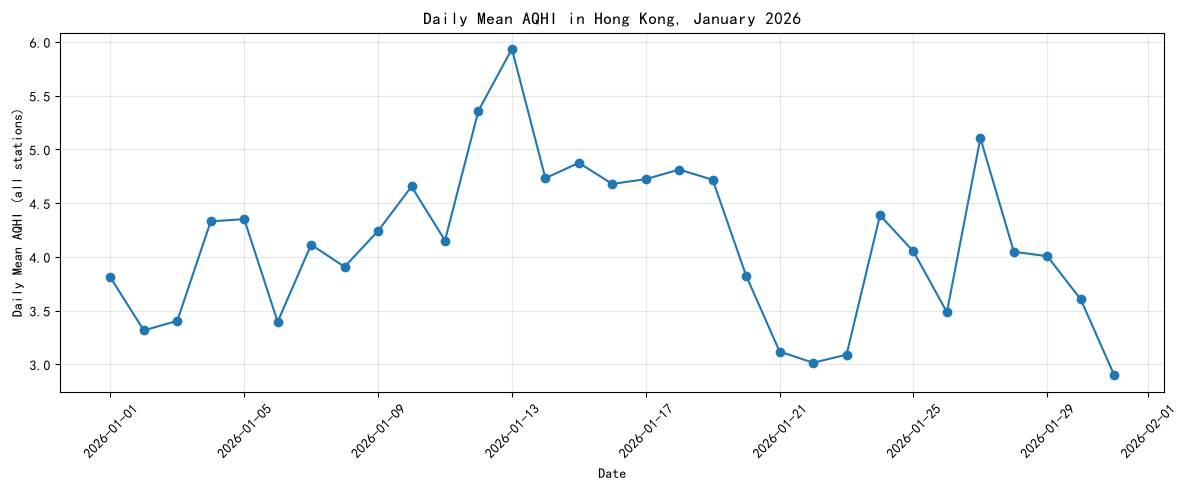

In [10]:
# Step 10: Draw Figure C, a line chart of daily mean AQHI across January, save and show it

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(pd.to_datetime(daily.index), daily.values, marker="o", linewidth=1.5)
ax.set_xlabel("Date")
ax.set_ylabel("Daily Mean AQHI (all stations)")
ax.set_title("Daily Mean AQHI in Hong Kong, January 2026")
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("fig2_daily_trend.png", dpi=150)  
plt.show()                                    


In [11]:
#Step 11: Print station averages and top/bottom days for README findings
print("=== Station mean AQHI (high to low) ===")
station_mean = df[station_cols].mean(numeric_only=True).sort_values(ascending=False)
print(station_mean)

print("\n=== Top 5 highest daily mean AQHI ===")
print(daily.sort_values(ascending=False).head())

print("\n=== Top 5 lowest daily mean AQHI ===")
print(daily.sort_values().head())

=== Station mean AQHI (high to low) ===
中环     4.470430
旺角     4.463710
屯门     4.444892
中西区    4.368280
铜锣湾    4.216398
观塘     4.205645
深水埗    4.193548
将军澳    4.157258
葵涌     4.134409
南区     4.133065
东区     4.127688
元朗     3.932796
荃湾     3.689516
东涌     3.331989
dtype: float64

=== Top 5 highest daily mean AQHI ===
日期
2026-01-13    5.934524
2026-01-12    5.360119
2026-01-27    5.104167
2026-01-15    4.875000
2026-01-18    4.812500
dtype: float64

=== Top 5 lowest daily mean AQHI ===
日期
2026-01-31    2.898810
2026-01-22    3.014881
2026-01-23    3.089286
2026-01-21    3.119048
2026-01-02    3.315476
dtype: float64


In [12]:
#Step 12: Verify both PNG files were created and are non-empty
import os
for f in ["fig1_station_boxplot.png", "fig2_daily_trend.png"]:
    print(f, os.path.exists(f), os.path.getsize(f) if os.path.exists(f) else 0)

fig1_station_boxplot.png True 76850
fig2_daily_trend.png True 103341
